# Capítulo 7: Tratamiento de datos, estadística descriptiva y visualización

In [1]:
# %pip funciona igual en VS Code y en Colab. Si ya está instalado, no hace nada.
%pip install pandas matplotlib openpyxl --quiet

In [2]:
import sys
import pandas as pd
import matplotlib
import numpy as np

print("Python    :", sys.version.split()[0])
print("pandas    :", pd.__version__)
print("numpy     :", np.__version__)
print("matplotlib:", matplotlib.__version__)

Python    : 3.13.18
pandas    : 2.2.3
numpy     : 2.4.6
matplotlib: 3.10.0


---
# Unidad 34: Uso de módulos de Python

## 1. ¿Qué es un módulo y por qué existen?

Un **módulo** es un archivo `.py` que agrupa **funciones, clases, variables y código ejecutable** para poder **reutilizarlo** desde otros programas.

> **Analogía:** una caja de herramientas. No fabricas un martillo cada vez que necesitas clavar un clavo: lo tomas de la caja.

### ¿Por qué son importantes?

| Razón | Qué significa en la práctica |
|---|---|
| **Reutilización** | Escribes una función una vez y la usas en 10 proyectos |
| **Organización** | Un archivo para cálculos, otro para gráficos, otro para datos |
| **Trabajo en equipo** | Cada persona trabaja su módulo sin pisar el de otra |
| **Evitar reinventar la rueda** | Python trae miles de módulos listos y la comunidad publica más de 500 000 paquetes |
| **Mantenimiento** | Si arreglas un error en el módulo, se arregla en todos los programas que lo usan |

> **Pandas, NumPy y Matplotlib que usaremos hoy son módulos.** Sin esta unidad no se puede entender cómo llegan a tu código.

## 2. Dos tipos de módulos

| | Estándar (integrados) | Externos (terceros) |
|---|---|---|
| **Vienen con Python** | Sí | No |
| **Instalación** | No hace falta | `pip install nombre` |
| **Dónde viven** | Dentro de Python | En **PyPI** (pypi.org), el repositorio público de paquetes |
| **Ejemplos** | `random`, `datetime`, `os`, `math`, `json`, `csv` | `pandas`, `numpy`, `matplotlib`, `requests`, `openpyxl` |

## 3. Cómo se importan

| Sintaxis | Uso | Ejemplo |
|---|---|---|
| `import modulo` | Trae el módulo completo; se usa con prefijo | `import math` → `math.sqrt(9)` |
| `from modulo import cosa` | Trae solo lo que necesitas; sin prefijo | `from math import sqrt` → `sqrt(9)` |
| `import modulo as alias` | Le pone un **apodo** corto | `import pandas as pd` |
| `from modulo import cosa as alias` | Apodo para algo concreto | `from datetime import datetime as dt` |

In [3]:
import math                      # módulo completo
from math import sqrt, pi        # solo lo que necesito
import datetime as dt            # con alias

print(math.sqrt(144))
print(sqrt(144))
print(pi)

# Ver qué contiene un módulo
print([nombre for nombre in dir(math) if not nombre.startswith("_")][:12])

12.0
12.0
3.141592653589793
['acos', 'acosh', 'asin', 'asinh', 'atan', 'atan2', 'atanh', 'cbrt', 'ceil', 'comb', 'copysign', 'cos']


> **Buena práctica:** no uses `from modulo import *`. Mezcla nombres de diferentes módulos y se vuelve imposible saber de dónde viene cada cosa.

## 4. Módulo `random`: azar para sorteos, simulaciones y pruebas

Funciones más usadas:

| Función | Qué hace |
|---|---|
| `random.sample(lista, k)` | Toma `k` elementos **distintos** al azar (sin repetir) |
| `random.choice(lista)` | Toma 1 elemento al azar |
| `random.randint(a, b)` | Entero al azar entre `a` y `b` (incluidos) |
| `random.shuffle(lista)` | Desordena la lista (la modifica) |
| `random.seed(n)` | Fija la "semilla" para que los resultados sean **repetibles** |

### Ejemplo real: sortear participantes y formar equipos

In [4]:
import random

estudiantes = ["Ana", "Luis", "María", "Carlos", "Sofía", "Diego",
               "Valeria", "Andrés", "Camila", "Mateo", "Lucía", "Pablo"]

# 1) Sortear 3 estudiantes para exponer (sin repetir)
expositores = random.sample(estudiantes, 3)
print("Exponen hoy:", expositores)

# 2) Formar equipos de 4 mezclando a todos
mezclados = random.sample(estudiantes, len(estudiantes))
equipos = [mezclados[i:i + 4] for i in range(0, len(mezclados), 4)]
for numero, equipo in enumerate(equipos, start=1):
    print(f"Equipo {numero}: {equipo}")

Exponen hoy: ['María', 'Sofía', 'Luis']
Equipo 1: ['Lucía', 'Valeria', 'María', 'Luis']
Equipo 2: ['Carlos', 'Diego', 'Ana', 'Sofía']
Equipo 3: ['Camila', 'Mateo', 'Andrés', 'Pablo']


### ¿Para qué sirve `random.seed`?
Para que un experimento sea **reproducible**: con la misma semilla, siempre sale lo mismo. Muy útil al enseñar o depurar.

In [5]:
random.seed(43)
print(random.sample(range(1, 50), 6))   # exactamente los mismos

[3, 19, 45, 10, 30, 24]


In [6]:
random.seed(42)
print(random.sample(range(1, 50), 6))   # "lotería" de 6 números

random.seed(42)
print(random.sample(range(1, 50), 6))   # exactamente los mismos

[41, 8, 2, 18, 16, 15]
[41, 8, 2, 18, 16, 15]


### Aplicación: simular datos para practicar
Cuando necesitas datos para probar tu código, `random` los genera en segundos.

In [7]:
random.seed(1)
ventas_simuladas = [random.randint(50, 200) for _ in range(7)]
print("Ventas de 7 días:", ventas_simuladas)

Ventas de 7 días: [84, 195, 66, 115, 80, 176, 165]


## 5. Módulo `datetime`: fechas y horas

Casi todo sistema real guarda fechas: pedidos, citas, registros, vencimientos.

| Objeto | Qué representa |
|---|---|
| `datetime.now()` | Fecha y hora actuales |
| `date(año, mes, día)` | Una fecha |
| `timedelta(days=…)` | Una **duración** (para sumar o restar tiempo) |
| `strftime(formato)` | Convierte una fecha **a texto** |
| `strptime(texto, formato)` | Convierte un texto **a fecha** |

Códigos de formato frecuentes: `%d` día, `%m` mes, `%Y` año, `%H` hora, `%M` minuto, `%A` día de la semana.

In [8]:
from datetime import datetime, date, timedelta

ahora = datetime.now()

print("Ahora        :", ahora)
print("Formateada   :", ahora.strftime("%H:%M %m/%Y"))
print("Año / mes    :", ahora.year, ahora.month)

# Texto -> fecha
nacimiento = datetime.strptime("27/11/2000", "%d/%m/%Y")
edad = (ahora - nacimiento).days // 365
print("Edad aprox.  :", edad, "años")

Ahora        : 2026-11-13 00:56:56.918013
Formateada   : 00:56 11/2026
Año / mes    : 2026 11
Edad aprox.  : 25 años


### Ejemplos reales: fecha de entrega y cuenta regresiva

In [9]:
hoy = date.today()

# 1) Fecha límite: 14 días a partir de hoy
entrega = hoy + timedelta(days=14)
print("Entrega el   :", entrega.strftime("%d/%m/%Y"))

# 2) ¿Cuántos días faltan para Navidad?
navidad = date(hoy.year, 12, 25)
if navidad < hoy:
    navidad = date(hoy.year + 1, 12, 25)
print("Faltan para Navidad:", (navidad - hoy).days, "días")

# 3) Día de la semana en español
dias = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
print("Hoy es", dias[hoy.weekday()])

Entrega el   : 27/11/2026
Faltan para Navidad: 42 días
Hoy es viernes


## 6. Módulo `os`: inspeccionar el entorno de trabajo

Un error muy común al empezar: *"FileNotFoundError: no encuentro mi archivo"*. Casi siempre pasa porque el programa está **buscando en una carpeta distinta** a la que crees.

| Función | Qué hace |
|---|---|
| `os.getcwd()` | Carpeta de trabajo actual (*current working directory*) |
| `os.listdir(ruta)` | Lista lo que hay en una carpeta |
| `os.path.exists(ruta)` | ¿Existe este archivo o carpeta? |
| `os.path.join(a, b)` | Une rutas correctamente en cualquier sistema operativo |
| `os.makedirs(ruta, exist_ok=True)` | Crea una carpeta (y no falla si ya existe) |

In [10]:
import os

print("Estoy en:", os.getcwd())
print("Contiene :", os.listdir(".")[:10])

Estoy en: /content
Contiene : ['.config', 'sample_data']


### Ejemplo real: ordenar archivos por tipo
Creamos una carpeta de prueba con varios archivos y contamos cuántos hay de cada extensión, como haría un organizador de descargas.

In [11]:
from collections import Counter

# Preparar una carpeta de práctica
os.makedirs("practica_os", exist_ok=True)
for nombre in ["notas.csv", "ventas.csv", "informe.xlsx", "foto1.png", "foto2.png", "foto3.png", "datos.json"]:
    with open(os.path.join("practica_os", nombre), "w") as f:
        f.write("contenido de prueba")

# Contar por extensión
archivos = os.listdir("practica_os")
extensiones = Counter(os.path.splitext(a)[1] for a in archivos)

print("Archivos:", sorted(archivos))
print("Por tipo:", dict(extensiones))

# Quedarnos solo con los CSV
csvs = [a for a in archivos if a.endswith(".csv")]
print("Archivos CSV:", csvs)

Archivos: ['datos.json', 'foto1.png', 'foto2.png', 'foto3.png', 'informe.xlsx', 'notas.csv', 'ventas.csv']
Por tipo: {'.xlsx': 1, '.json': 1, '.png': 3, '.csv': 2}
Archivos CSV: ['ventas.csv', 'notas.csv']


---

## 7. Módulos externos: instalar con `pip`

`pip` es el **instalador de paquetes** de Python. Descarga desde **PyPI**.

| Comando | Para qué |
|---|---|
| `pip install pandas` | Instalar |
| `pip install pandas==2.2.0` | Instalar una versión concreta |
| `pip install --upgrade pandas` | Actualizar |
| `pip uninstall pandas` | Desinstalar |
| `pip list` | Ver lo instalado |
| `pip show pandas` | Ver versión y detalles de un paquete |
| `pip freeze > requirements.txt` | Guardar la lista de paquetes del proyecto |

> En **Jupyter / Colab / VS Code (cuaderno)** usa `%pip install ...` en lugar de `pip install ...`, para que se instale en el entorno que está ejecutando el cuaderno.

### Error clásico: `ModuleNotFoundError`
Significa que el módulo **no está instalado** en ese entorno. La solución casi siempre es `pip install`.

In [12]:
try:
    import paquete_que_no_existe
except ModuleNotFoundError as error:
    print("Error:", error)
    print("Solución: instalarlo con  %pip install nombre_del_paquete")

Error: No module named 'paquete_que_no_existe'
Solución: instalarlo con  %pip install nombre_del_paquete


In [13]:
# Ver detalles de un paquete instalado
%pip show pandas

Name: pandas
Version: 2.2.3
Summary: Powerful data structures for data analysis, time series, and statistics
Home-page: https://pandas.pydata.org
Author: 
Author-email: The Pandas Development Team <pandas-dev@python.org>
License: BSD 3-Clause License

Copyright (c) 2008-2011, AQR Capital Management, LLC, Lambda Foundry, Inc. and PyData Development Team
All rights reserved.

Copyright (c) 2011-2023, Open source contributors.

Redistribution and use in source and binary forms, with or without
modification, are permitted provided that the following conditions are met:

* Redistributions of source code must retain the above copyright notice, this
  list of conditions and the following disclaimer.

* Redistributions in binary form must reproduce the above copyright notice,
  this list of conditions and the following disclaimer in the documentation
  and/or other materials provided with the distribution.

* Neither the name of the copyright holder nor the names of its
  contributors may be u

## 8. Crear tu propio módulo

Cualquier archivo `.py` es un módulo. Vamos a crear uno con funciones de utilidad para notas escolares y a importarlo.

In [14]:
codigo_modulo = '''
# utilidades.py

NOTA_MINIMA = 60

def promedio(notas):
    return sum(notas) / len(notas)

def aprobado(nota):
    return nota >= NOTA_MINIMA

def clasificar(nota):
    if nota >= 90:
        return "Excelente"
    elif nota >= 75:
        return "Bueno"
    elif nota >= NOTA_MINIMA:
        return "Suficiente"
    return "Reprobado"
'''

with open("utilidades.py", "w", encoding="utf-8") as archivo:
    archivo.write(codigo_modulo)

print("Archivos .py en la carpeta:", [a for a in os.listdir(".") if a.endswith(".py")])

Archivos .py en la carpeta: ['utilidades.py']


In [15]:
import utilidades

notas = [85, 92, 70, 58, 100]
print("Promedio:", utilidades.promedio(notas))
for n in notas:
    print(n, "->", utilidades.clasificar(n))

Promedio: 81.0
85 -> Bueno
92 -> Excelente
70 -> Suficiente
58 -> Reprobado
100 -> Excelente


In [16]:
from utilidades import aprobado, NOTA_MINIMA

print("Nota mínima:", NOTA_MINIMA)
print("¿58 aprueba?", aprobado(58))

Nota mínima: 60
¿58 aprueba? False


---
# Unidad 35: Pandas y la estructura `Series`

## 1. ¿Qué es Pandas?

**Pandas** es la biblioteca de Python más usada para **manipular, limpiar y analizar datos estructurados** (tablas, hojas de cálculo, archivos CSV, bases de datos y series temporales).

> Si Excel es una hoja de cálculo que manejas con el ratón, Pandas es una hoja de cálculo que manejas con código: **más rápida, repetible y capaz de trabajar con millones de filas**.

Su nombre viene de *panel data* (datos de panel, un término de econometría).

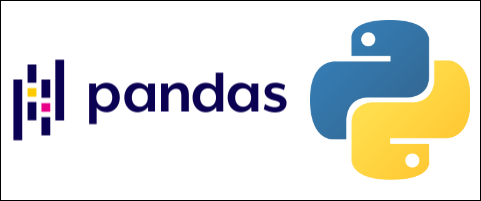

### ¿Para qué se usa?

| Área | Ejemplo |
|---|---|
| **Negocios** | Analizar ventas por producto, mes o sucursal |
| **Educación** | Procesar notas, asistencia y rendimiento de grupos |
| **Finanzas** | Precios de acciones, inflación, tasas de cambio |
| **Ciencia** | Procesar datos de experimentos |
| **Salud** | Estudiar registros de pacientes (datos anonimizados) |
| **Inteligencia Artificial** | **Preparar y limpiar los datos** antes de entrenar un modelo |
| **Automatización** | Reemplazar tareas repetitivas de Excel |


### ¿Qué ventajas tiene frente a Excel?

| Pandas | Excel |
|---|---|
| Millones de filas sin problema | Se vuelve lento con muchos datos |
| El análisis queda en un **script repetible** | Hay que repetir los clics cada vez |
| Lee CSV, Excel, JSON, SQL, web... | Principalmente archivos de Excel |
| Fácil de combinar con gráficos y modelos de IA | Más limitado |


### Instalación (recordatorio)

- **Colab:** ya viene instalado.
- **VS Code:** `pip install pandas matplotlib openpyxl` en la terminal con el entorno activado (ver Sección 0).
- **Conda:** `conda install pandas`.

**Dependencias opcionales útiles**

| Paquete | Para qué |
|---|---|
| `numpy` | Cálculo numérico (Pandas lo instala solo) |
| `matplotlib` | Gráficos |
| `openpyxl` | Leer y escribir archivos **Excel** (`.xlsx`) |
| `scipy` | Estadística y ciencia avanzada |
| `seaborn` | Gráficos estadísticos más vistosos |

Por convención, **siempre** se importa así:

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Pandas listo, versión", pd.__version__)

Pandas listo, versión 2.2.3


## 2. La estructura `Series`

Una **Series** es un **arreglo unidimensional con etiquetas**. Cada dato está unido a un **índice** (su "dirección").

```
índice   dato
 Lun      120
 Mar      135       ← una Series: una sola columna de datos, con nombres para cada fila
 Mié      110
```

Piensa en ella como **una columna de Excel** donde cada fila tiene un nombre.

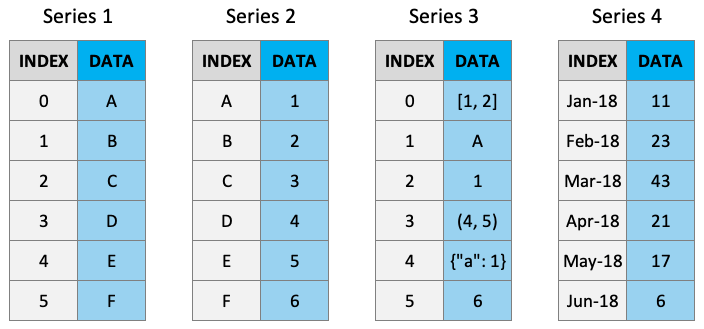

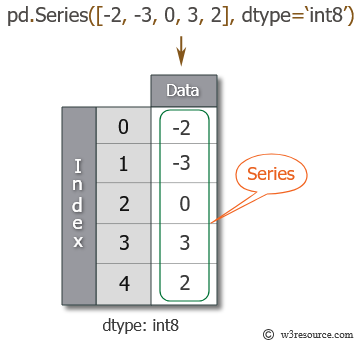

### 2.1 Formas de crear una Series

In [18]:
# 1) Desde una lista (el índice es 0, 1, 2... por defecto)
serie1 = pd.Series([120, 135, 110, 150])
print(serie1, "\n**********")

0    120
1    135
2    110
3    150
dtype: int64 
**********


In [19]:
# 2) Desde una lista con índice propio
s2 = pd.Series([120, 135, 110, 150], index=["Lun", "Mar", "Mié", "Jue"])
print(s2, "\n**********")

Lun    120
Mar    135
Mié    110
Jue    150
dtype: int64 
**********


In [20]:
# 3) Desde un diccionario (las claves pasan a ser el índice)
s3 = pd.Series({"Lunes": 120, "Martes": 135, "Miércoles": 110, "Jueves": 150})
print(s3, "\n**********")

Lunes        120
Martes       135
Miércoles    110
Jueves       150
dtype: int64 
**********


In [21]:
# 4) Desde un arreglo de NumPy
s4 = pd.Series(np.array([1.5, 2.5, 3.5]), index=["a", "b", "c"])
print(s4, "\n**********")

a    1.5
b    2.5
c    3.5
dtype: float64 
**********


In [22]:
# 5) Desde un valor escalar (se repite en todo el índice)
s5 = pd.Series(10, index=["x", "y", "z", "w"])
print(s5)

x    10
y    10
z    10
w    10
dtype: int64


### 2.2 Atributos principales: `.index`, `.values`, `.name`, `.dtype`

In [23]:
ventas = pd.Series([120, 135, 110, 150, 180, 220, 90],
                   index=["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"],
                   name="Ventas de la semana")

print("Índice :", ventas.index)
print("*"*80)
print("Valores:", ventas.values)
print("*"*80)
print("Nombre :", ventas.name)
print("*"*80)
print("Tipo   :", ventas.dtype)
print("*"*80)
print("Tamaño :", ventas.size)

Índice : Index(['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom'], dtype='object')
********************************************************************************
Valores: [120 135 110 150 180 220  90]
********************************************************************************
Nombre : Ventas de la semana
********************************************************************************
Tipo   : int64
********************************************************************************
Tamaño : 7


### 2.3 Selección de elementos: por posición y por etiqueta

| Acceso | Cómo | Ejemplo |
|---|---|---|
| Por **etiqueta** | `.loc[...]` | `ventas.loc["Vie"]` |
| Por **posición** | `.iloc[...]` | `ventas.iloc[4]` |
| Varios elementos | lista de etiquetas | `ventas[["Lun", "Vie"]]` |
| Rango por posición | `.iloc[a:b]` | `ventas.iloc[0:3]` |
| Rango por etiqueta | `.loc[a:b]` | `ventas.loc["Lun":"Mié"]` (**incluye** el final) |
| Por condición | filtro | `ventas[ventas > 150]` |

> **Recomendación:** usa siempre `.loc` (etiqueta) y `.iloc` (posición). Así no hay ambigüedad.

In [24]:
print("Viernes (etiqueta)   :", ventas.loc["Vie"])
print("5.º elemento (pos.)  :", ventas.iloc[4])
print()
print("Lunes y Sábado:\n", ventas[["Lun", "Sáb"]], "\n")
print("Primeros tres días:\n", ventas.iloc[0:3], "\n")
print("De Lun a Mié (incluye Mié):\n", ventas.loc["Lun":"Mié"])

Viernes (etiqueta)   : 180
5.º elemento (pos.)  : 180

Lunes y Sábado:
 Lun    120
Sáb    220
Name: Ventas de la semana, dtype: int64 

Primeros tres días:
 Lun    120
Mar    135
Mié    110
Name: Ventas de la semana, dtype: int64 

De Lun a Mié (incluye Mié):
 Lun    120
Mar    135
Mié    110
Name: Ventas de la semana, dtype: int64


In [25]:
# Filtrar por condición: ¿qué días vendí más de 150?
print("Días de ventas altas:")
print(ventas[ventas > 150])

# ¿Qué días vendí entre 100 y 150?
print("\nDías de ventas medias:")
print(ventas[(ventas >= 100) & (ventas <= 150)])

Días de ventas altas:
Vie    180
Sáb    220
Name: Ventas de la semana, dtype: int64

Días de ventas medias:
Lun    120
Mar    135
Mié    110
Jue    150
Name: Ventas de la semana, dtype: int64


## 3. Operaciones aritméticas

### 3.1 Con un escalar
La operación se aplica **a todos los elementos a la vez** (esto se llama *vectorización* y evita escribir bucles).

In [26]:
print("Ventas con 10 % de aumento:")
print((ventas * 1.10).round(1))

print("\nVentas en miles (dividido entre 1000):")
print(ventas / 1000)

Ventas con 10 % de aumento:
Lun    132.0
Mar    148.5
Mié    121.0
Jue    165.0
Vie    198.0
Sáb    242.0
Dom     99.0
Name: Ventas de la semana, dtype: float64

Ventas en miles (dividido entre 1000):
Lun    0.120
Mar    0.135
Mié    0.110
Jue    0.150
Vie    0.180
Sáb    0.220
Dom    0.090
Name: Ventas de la semana, dtype: float64


### 3.2 Entre dos Series y **alineación automática por índice**

Cuando operas dos Series, Pandas **empareja por etiqueta** (no por posición). Si una etiqueta no existe en la otra, el resultado es **`NaN`** (*Not a Number*, dato faltante).

**Ejemplo real:** dos sucursales de una tienda. La sucursal B no abrió el domingo, y tiene un día extra (feriado).

In [27]:
sucursal_a = pd.Series({"Lun": 120, "Mar": 135, "Mié": 110, "Jue": 150, "Dom": 90, "Vie": 90, })
sucursal_b = pd.Series({"Lun": 80,  "Mar": 95,  "Mié": 70,  "Jue": 100, "Feriado": 60})

total = sucursal_a + sucursal_b
print(total)

Dom          NaN
Feriado      NaN
Jue        250.0
Lun        200.0
Mar        230.0
Mié        180.0
Vie          NaN
dtype: float64


Los días que no coinciden quedan como `NaN`. Tenemos tres formas de tratarlos:

> **fillna(0):** Cambia todos los espacios vacíos (NaN) por un cero para que la tabla quede completa.

> **dropna():** Elimina por completo cualquier fila que tenga un espacio vacío.

> **add(fill_value=0):** Suma dos tablas y, si a una de las dos le falta un dato, le pone un cero temporal para poder hacer la suma sin errores.

> **isna():** Revisa toda la tabla y te avisa con un "Verdadero" (True) dónde están los espacios vacíos.

In [28]:
# a) Reemplazar los faltantes por un valor
print("fillna(0):\n",total.fillna(0), "\n")

fillna(0):
 Dom          0.0
Feriado      0.0
Jue        250.0
Lun        200.0
Mar        230.0
Mié        180.0
Vie          0.0
dtype: float64 



In [29]:
# b) Descartar los faltantes
print("dropna():\n", total.dropna(), "\n")

dropna():
 Jue    250.0
Lun    200.0
Mar    230.0
Mié    180.0
dtype: float64 



In [30]:
# c) Sumar considerando los faltantes como 0 desde el principio
print("add(fill_value=0):\n", sucursal_a.add(sucursal_b, fill_value=0), "\n")

add(fill_value=0):
 Dom         90.0
Feriado     60.0
Jue        250.0
Lun        200.0
Mar        230.0
Mié        180.0
Vie         90.0
dtype: float64 



In [31]:
# Detectar faltantes
print("¿Cuáles son NaN?\n", total.isna())

¿Cuáles son NaN?
 Dom         True
Feriado     True
Jue        False
Lun        False
Mar        False
Mié        False
Vie         True
dtype: bool


> **¿Por qué es útil la alineación?** En datos reales, dos tablas casi nunca tienen exactamente las mismas filas. Pandas hace el emparejamiento por ti y evita errores silenciosos de "sumar la fila equivocada".

---

## 4. Estadística descriptiva con una Series

La **estadística descriptiva** resume un conjunto de datos en pocos números.

| Método | Qué calcula | En palabras sencillas |
|---|---|---|
| `count()` | Cantidad de datos (sin `NaN`) | ¿Cuántos hay? |
| `sum()` | Suma | Total |
| `mean()` | Media | Promedio |
| `median()` | Mediana | El valor del medio (no la afectan los extremos) |
| `mode()` | Moda | El valor que más se repite |
| `std()` | Desviación estándar | ¿Qué tan dispersos están los datos? |
| `min()` / `max()` | Mínimo / máximo | Menor / mayor |
| `cumsum()` | Suma acumulada | Total "hasta ahora" |
| `idxmax()` / `idxmin()` | **Etiqueta** del máximo / mínimo | ¿**Cuál** fue el mejor día? |
| `describe()` | Resumen completo | Todo lo anterior de una vez |

In [32]:
print("Cantidad      :", ventas.count())
print("Total         :", ventas.sum())
print("Promedio      :", round(ventas.mean(), 2))
print("Mediana       :", ventas.median())
print("Desv. estándar:", round(ventas.std(), 2))
print("Mínimo        :", ventas.min(), "->", ventas.idxmin())
print("Máximo        :", ventas.max(), "->", ventas.idxmax())

Cantidad      : 7
Total         : 1005
Promedio      : 143.57
Mediana       : 135.0
Desv. estándar: 44.41
Mínimo        : 90 -> Dom
Máximo        : 220 -> Sáb


In [33]:
print("Ventas acumuladas durante la semana:")
print(ventas.cumsum())

Ventas acumuladas durante la semana:
Lun     120
Mar     255
Mié     365
Jue     515
Vie     695
Sáb     915
Dom    1005
Name: Ventas de la semana, dtype: int64


In [34]:
# Todo de una vez
print(ventas.describe())

count      7.000000
mean     143.571429
std       44.414176
min       90.000000
25%      115.000000
50%      135.000000
75%      165.000000
max      220.000000
Name: Ventas de la semana, dtype: float64


### La moda: cuándo importa
La **moda** es útil con datos que se repiten, por ejemplo la **talla más vendida** o la **nota más frecuente**.

In [35]:
tallas_vendidas = pd.Series(["M", "L", "M", "S", "M", "L", "XL", "M", "S", "L"])
print("Talla más vendida:", tallas_vendidas.mode()[0])
print()
print("Conteo por talla:")
print(tallas_vendidas.value_counts())

Talla más vendida: M

Conteo por talla:
M     4
L     3
S     2
XL    1
Name: count, dtype: int64


### ¿Media o mediana? Un caso real

Si en un grupo de salarios hay **un valor extremo**, la media se distorsiona y la **mediana** representa mejor al grupo.

In [36]:
salarios = pd.Series([800, 850, 900, 950, 1000, 12000])   # el último es un gerente
print("Media  :", round(salarios.mean(), 1), " <- la inflan los 12000")
print("Mediana:", salarios.median(), " <- representa mejor al grupo típico")

Media  : 2750.0  <- la inflan los 12000
Mediana: 925.0  <- representa mejor al grupo típico


## 5. Gráficos con Pandas + Matplotlib

**Matplotlib** es la biblioteca base de gráficos de Python. Se importa como `plt`.

| Gráfico | Cuándo usarlo | Código |
|---|---|---|
| **Línea** | Evolución en el tiempo | `plt.plot(x, y)` |
| **Barras verticales** | Comparar categorías | `plt.bar(x, y)` |
| **Barras horizontales** | Comparar categorías con **nombres largos** | `plt.barh(x, y)` |

> Un buen gráfico siempre lleva: **título, etiquetas en los ejes** y, si hay varias series, **leyenda**.

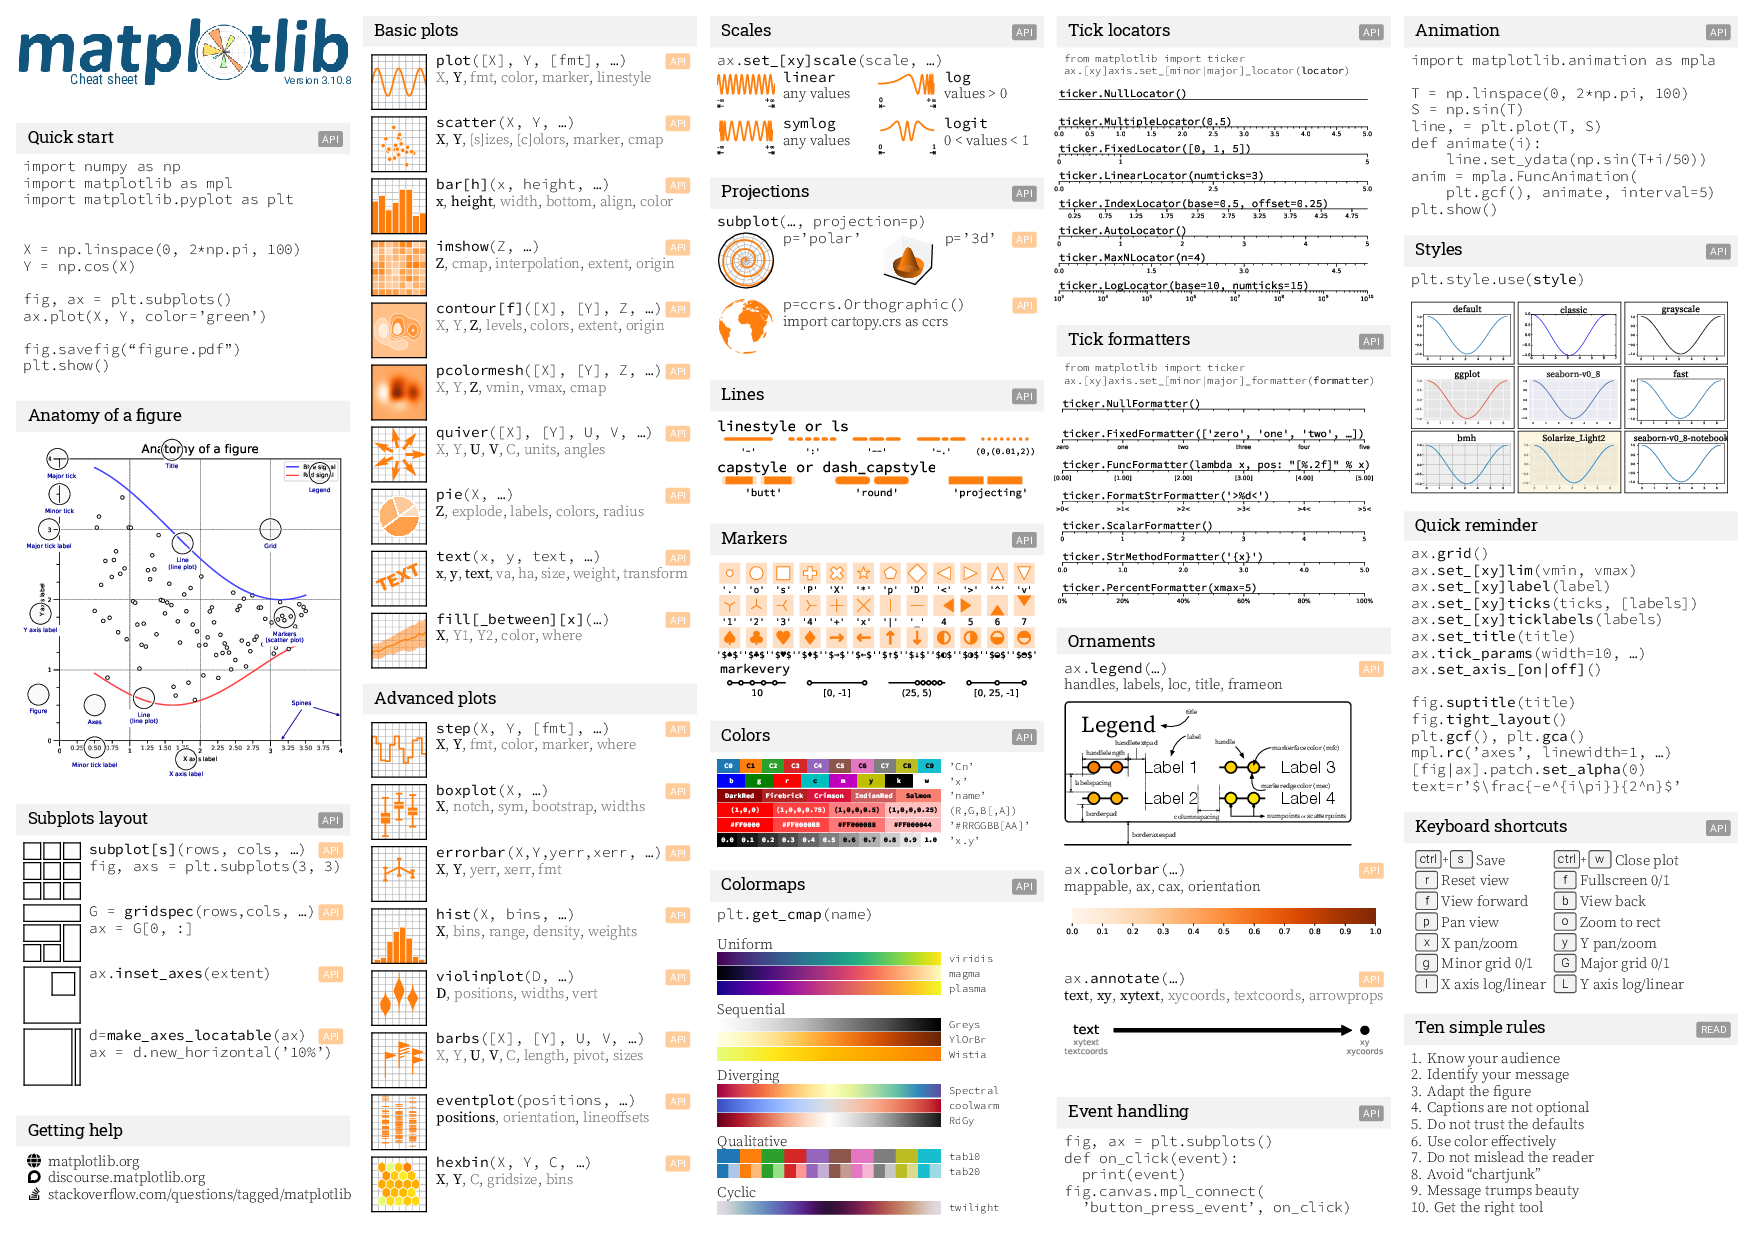

### 5.1 Gráfico de líneas: evolución de las ventas

> **plt.figure(figsize=(8, 4)):** Crea el lienzo y define el tamaño del gráfico (8 de ancho por 4 de alto).

> **plt.plot(...):** Dibuja la línea usando los días en el eje X, el dinero en el eje Y, con puntos circulares (marker='o') y de color azul.

> **plt.title(...):** Pone el título principal arriba del gráfico.

> **plt.xlabel(...):** Nombra el eje X (horizontal) como "Día".

> **plt.ylabel(...):** Nombra el eje Y (vertical) como "Ventas ($)".

> **plt.grid(alpha=0.3):** Activa la cuadrícula de fondo de forma tenue (70% transparente).

> **plt.show():** Muestra el gráfico final en la pantalla.

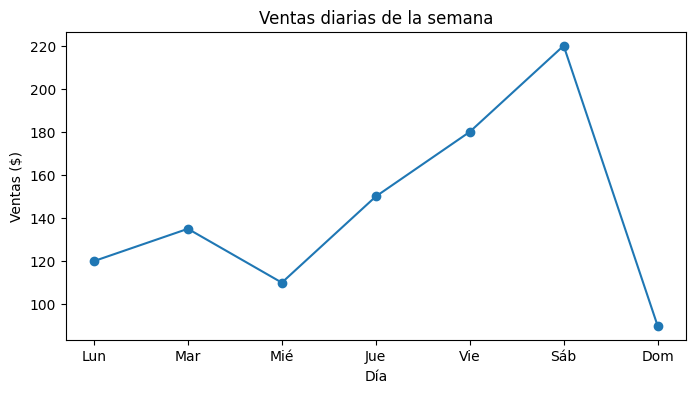

In [37]:
plt.figure(figsize=(8, 4))
plt.plot(ventas.index, ventas.values, marker="o", color="tab:blue")
plt.title("Ventas diarias de la semana")
plt.xlabel("Día")
plt.ylabel("Ventas ($)")
plt.show()

### 5.2 Barras: comparar días

> **plt.bar(...):** Dibuja las barras verticales usando los días en el eje X, el dinero en el eje Y y de color verde.

> **plt.axhline(...):** Traza una línea horizontal roja y discontinua (--) que marca el promedio de las ventas, poniéndole una etiqueta con su valor redondeado.

> **plt.legend():** Muestra la leyenda en el gráfico para que se sepa qué significa la línea roja del promedio.

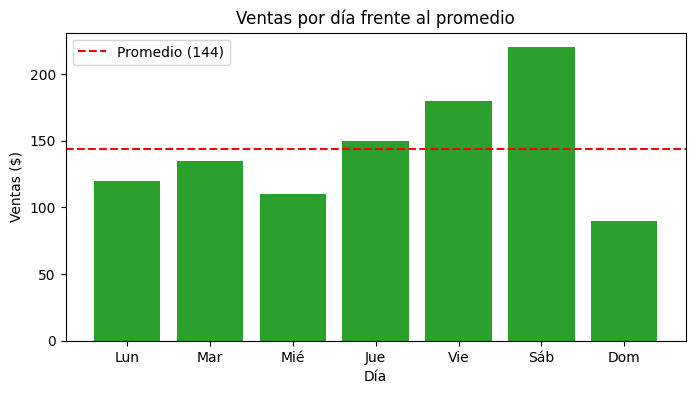

In [38]:
plt.figure(figsize=(8, 4))
plt.bar(ventas.index, ventas.values, color="tab:green")
plt.axhline(ventas.mean(), color="red", linestyle="--", label=f"Promedio ({ventas.mean():.0f})")
plt.title("Ventas por día frente al promedio")
plt.xlabel("Día")
plt.ylabel("Ventas ($)")
plt.legend()
plt.show()

### 5.3 Barras horizontales: ranking
Ideales cuando los nombres son largos, como productos o países.

> **plt.barh(...):** Dibuja barras horizontales usando los nombres de los productos en el eje Y, las cantidades en el eje X y de color naranja.

> **plt.xlabel(...):** Nombra el eje X (horizontal) como "Unidades vendidas" (en este gráfico de barras horizontales, el eje X ahora representa la cantidad y el eje Y los productos).

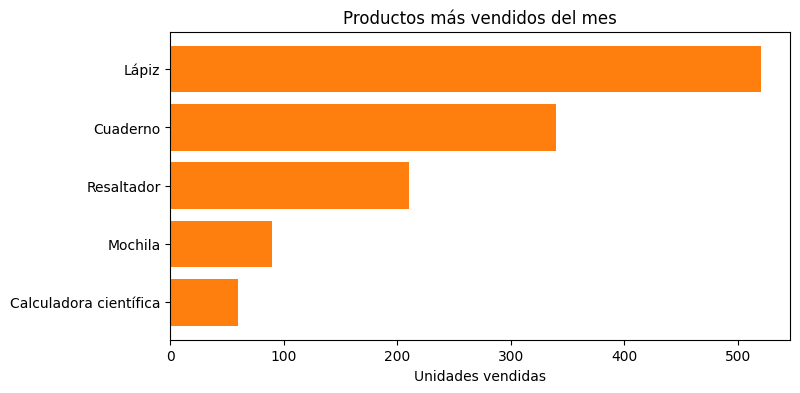

In [39]:
productos = pd.Series({"Cuaderno": 340, "Lápiz": 520, "Mochila": 90,
                       "Calculadora científica": 60, "Resaltador": 210})
productos = productos.sort_values()      # ordenar para que el ranking se lea bien

plt.figure(figsize=(8, 4))
plt.barh(productos.index, productos.values, color="tab:orange")
plt.title("Productos más vendidos del mes")
plt.xlabel("Unidades vendidas")
plt.show()

> **Atajo:** las Series de Pandas ya tienen su propio método de gráfico: `ventas.plot()` (líneas), `ventas.plot.bar()`, `ventas.plot.barh()`. Por debajo usan Matplotlib.

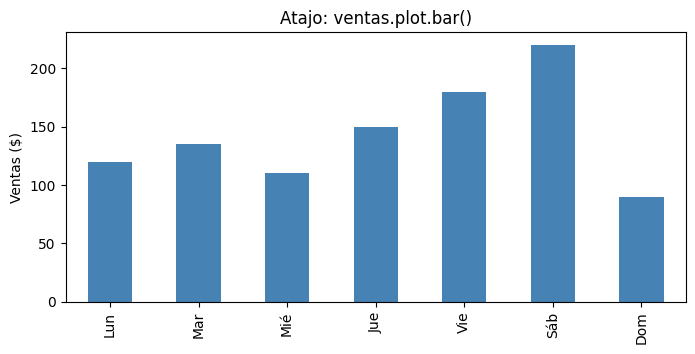

In [40]:
ventas.plot.bar(figsize=(8, 3.5), color="steelblue", title="Atajo: ventas.plot.bar()")
plt.ylabel("Ventas ($)")
plt.show()

## 6. Mini-proyecto de la unidad: resumen semanal automático

Con lo visto podemos construir una función que reciba **cualquier** Series de ventas y dé un reporte de texto.

---
# Unidad 36: Pandas `DataFrame`

## 1. ¿Qué es un DataFrame?

Un **DataFrame** es una **tabla bidimensional**: filas y columnas, como una hoja de Excel o una tabla de base de datos. Es **la estructura más usada en ciencia de datos**.

| Parte | Nombre técnico | Ejemplo |
|---|---|---|
| **Fila** | Observación / instancia / registro | Un estudiante |
| **Columna** | Variable / característica / atributo | Su nota de matemáticas |
| **Etiquetas de filas** | `index` | 0, 1, 2... o un nombre |
| **Etiquetas de columnas** | `columns` | "nombre", "nota" |

> **Relación con la unidad anterior:** **cada columna de un DataFrame es una `Series`**. Todo lo que aprendiste (`mean()`, filtros, `idxmax()`, gráficos) funciona igual en las columnas.

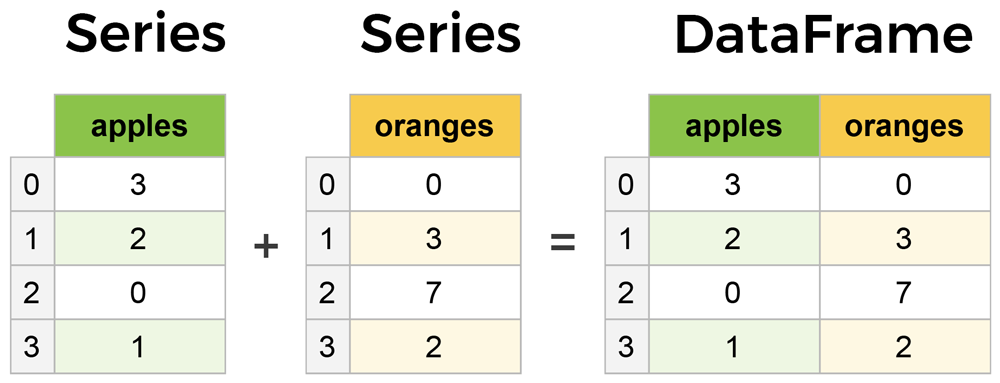

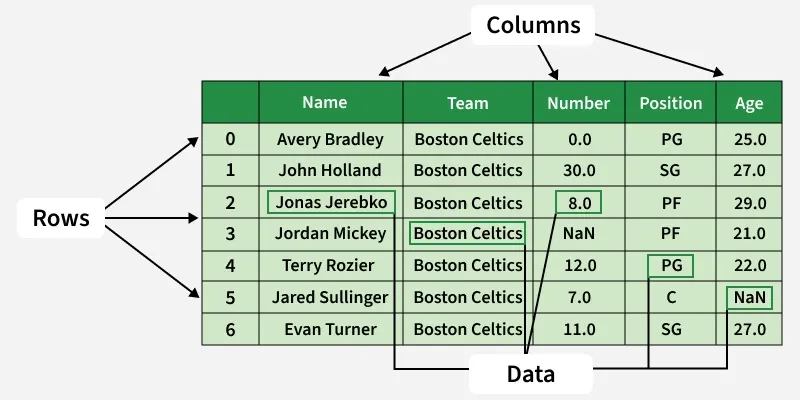

## 2. Crear un DataFrame

### 2.1 Desde un diccionario de listas
Cada **clave** es una columna.

In [41]:
datos = {
    "estudiante": ["Ana", "Luis", "María", "Carlos", "Sofía", "Diego","Valeria", "Andrés", "Camila", "Mateo", "Lucía", "Pablo"],
    "grupo": ["A", "A", "A", "A", "B", "B", "B", "B", "C", "C", "C", "C"],
    "horas_estudio": [10, 4, 12, 3, 8, 6, 14, 2, 9, 5, 11, 7],
    "nota_matematica": [88, 62, 95, 55, 80, 70, 98, 50, 85, 66, 92, 74],
    "nota_programacion": [90, 58, 97, 60, 84, 72, 95, 48, 82, 70, 94, 71],
    "asistencia": [95, 70, 100, 65, 90, 80, 100, 60, 92, 75, 98, 85],
}

df = pd.DataFrame(datos)
df

,estudiante,grupo,horas_estudio,nota_matematica,nota_programacion,asistencia
0,Ana,A,10,88,90,95
1,Luis,A,4,62,58,70
2,María,A,12,95,97,100
3,Carlos,A,3,55,60,65
4,Sofía,B,8,80,84,90
5,Diego,B,6,70,72,80
6,Valeria,B,14,98,95,100
7,Andrés,B,2,50,48,60
8,Camila,C,9,85,82,92
9,Mateo,C,5,66,70,75


### 2.2 Con `pd.DataFrame.from_dict()`
Hace lo mismo y permite orientar el diccionario por filas (`orient="index"`) si cada clave es una fila.

In [42]:
# Cada clave es una FILA (estudiante) y el valor, sus datos
por_filas = pd.DataFrame.from_dict(
    {
        "Ana":  {"matematica": 88, "programacion": 90},
        "Luis": {"matematica": 62, "programacion": 58},
        "María": {"matematica": 95, "programacion": 97},
    },
    orient="index",
)
por_filas

,matematica,programacion
Ana,88,90
Luis,62,58
María,95,97


### 2.3 Desde varias Series

In [43]:
nombres = pd.Series(["Ana", "Luis", "María"])
edades = pd.Series([20, 22, 21])
pd.DataFrame({"nombre": nombres, "edad": edades})

,nombre,edad
0,Ana,20
1,Luis,22
2,María,21


## 3. Cargar datos desde archivos (API de entrada/salida de Pandas)

En el mundo real los datos casi siempre **vienen de un archivo**. Pandas lee los formatos más comunes:

| Formato | Leer | Escribir | Necesita |
|---|---|---|---|
| **CSV** (texto separado por comas) | `pd.read_csv()` | `df.to_csv()` | — |
| **Excel** | `pd.read_excel()` | `df.to_excel()` | `openpyxl` |
| **JSON** | `pd.read_json()` | `df.to_json()` | — |
| **SQL** | `pd.read_sql()` | `df.to_sql()` | Conexión a base de datos |



### 3.1 `read_csv()` y sus parámetros más importantes

| Parámetro | Para qué sirve | Ejemplo |
|---|---|---|
| `sep` | Separador de columnas (`,` `;` `\t`) | `sep=";"` |
| `header` | Fila que contiene los nombres de columna (`None` si no hay) | `header=None` |
| `index_col` | Columna que se usa como índice | `index_col="estudiante"` |
| `encoding` | Codificación del texto (tildes y ñ) | `encoding="latin-1"` |
| `skiprows` | Saltar filas del inicio | `skiprows=2` |
| `nrows` | Leer solo las primeras N filas | `nrows=100` |

Para practicar sin descargar nada, **primero creamos un CSV** (simulando el archivo que te daría otro sistema, con `;` como separador y una línea de encabezado de reporte al inicio).

In [44]:
# Archivo CSV "problemático" como los que se ven en la vida real:
# - 1.ª línea es un título del reporte (hay que saltarla)
# - separador ";" (típico de Excel en español)
# - codificación latin-1 (por las tildes y ñ)

lineas = [
    "REPORTE DE NOTAS - CURSO PYTHON",
    "estudiante;grupo;horas_estudio;nota_matematica;nota_programacion;asistencia",
]

for i in range(len(datos["estudiante"])):
    fila = [str(datos[col][i]) for col in datos]
    lineas.append(";".join(fila))

with open("notas.csv", "w", encoding="latin-1") as f:
    f.write("\n".join(lineas))

print(open("notas.csv", encoding="latin-1").read()[:300])

REPORTE DE NOTAS - CURSO PYTHON
estudiante;grupo;horas_estudio;nota_matematica;nota_programacion;asistencia
Ana;A;10;88;90;95
Luis;A;4;62;58;70
María;A;12;95;97;100
Carlos;A;3;55;60;65
Sofía;B;8;80;84;90
Diego;B;6;70;72;80
Valeria;B;14;98;95;100
Andrés;B;2;50;48;60
Camila;C;9;85;82;92
Mateo;C;5;66;7


### Lo que pasa si lo leemos sin parámetros

In [45]:
try:
    pd.read_csv("notas.csv")
except Exception as error:
    print(type(error).__name__, "->", str(error)[:120])

UnicodeDecodeError -> 'utf-8' codec can't decode byte 0xed in position 147: invalid continuation byte


Es el error de **codificación** (`UnicodeDecodeError`). Pandas esperaba UTF-8 y el archivo está en latin-1. Ahora lo leemos bien, paso a paso:

In [46]:
# Paso 1: solo la codificación
try:
    paso1 = pd.read_csv("notas.csv", encoding="latin-1")
    print(paso1.head(3))
except Exception as error:
    print("Aún falla:", error)

print("-" * 60)

# Paso 2: + saltar la línea de título + separador correcto
notas = pd.read_csv("notas.csv", encoding="latin-1", sep=";", skiprows=1)
print(notas.head(3))

                     REPORTE DE NOTAS - CURSO PYTHON
0  estudiante;grupo;horas_estudio;nota_matematica...
1                                  Ana;A;10;88;90;95
2                                  Luis;A;4;62;58;70
------------------------------------------------------------
  estudiante grupo  horas_estudio  nota_matematica  nota_programacion  \
0        Ana     A             10               88                 90   
1       Luis     A              4               62                 58   
2      María     A             12               95                 97   

   asistencia  
0          95  
1          70  
2         100  


In [47]:
# Otros parámetros: index_col, nrows
a = pd.read_csv("notas.csv", encoding="latin-1", sep=";", skiprows=1, index_col="estudiante")
print(a.head(3), "\n")

b = pd.read_csv("notas.csv", encoding="latin-1", sep=";", skiprows=1, nrows=4)
print("Solo las primeras 4 filas:", len(b))

           grupo  horas_estudio  nota_matematica  nota_programacion  \
estudiante                                                            
Ana            A             10               88                 90   
Luis           A              4               62                 58   
María          A             12               95                 97   

            asistencia  
estudiante              
Ana                 95  
Luis                70  
María              100   

Solo las primeras 4 filas: 4


> **Consejo:** cuando un CSV se ve raro (todo en una sola columna, símbolos extraños, filas de más), el problema casi siempre está en `sep`, `encoding` o `skiprows`.

### 3.2 `read_excel()` y `read_json()`

In [48]:
# Guardamos y volvemos a leer, para ver el ciclo completo
df.to_excel("notas.xlsx", index=False, sheet_name="Notas")
desde_excel = pd.read_excel("notas.xlsx", sheet_name="Notas")
print("Excel :", desde_excel.shape)

df.to_json("notas.json", orient="records", force_ascii=False)
desde_json = pd.read_json("notas.json")
print("JSON  :", desde_json.shape)

print(open("notas.json", encoding="utf-8").read()[:150], "...")

Excel : (12, 6)
JSON  : (12, 6)
[{"estudiante":"Ana","grupo":"A","horas_estudio":10,"nota_matematica":88,"nota_programacion":90,"asistencia":95},{"estudiante":"Luis","grupo":"A","hor ...


### 3.3 Cargar desde internet y repositorios remotos

`pd.read_csv` acepta directamente una **URL**. Es muy útil con datos abiertos (gobiernos, organismos, GitHub).

```python
url = "https://raw.githubusercontent.com/usuario/repo/main/datos.csv"
df = pd.read_csv(url)
```

Además existe la biblioteca **`pandas_datareader`**, que descarga datos de fuentes como el **Banco Mundial** o **FRED** (Reserva Federal de EE. UU.):



In [ ]:
%pip install pandas_datareader
from pandas_datareader import wb

# PIB per cápita (USD actuales) de varios países
datos_pib = wb.download(indicator="NY.GDP.PCAP.CD",
                        country=["PA", "GT", "CR"],
                        start=2010, end=2022)

> Requiere internet y depende de que la fuente esté disponible y de la versión de la librería. Si falla, es normal; por eso en este cuaderno no la ejecutamos automáticamente. Una alternativa estable es descargar el CSV desde el sitio del organismo y usar read_csv.

---

## 4. Inspección y exploración rápida

La **primera cosa** que haces con cualquier dataset nuevo es **mirarlo**.

| Herramienta | Qué muestra |
|---|---|
| `df.head(n)` | Primeras `n` filas (5 por defecto) |
| `df.tail(n)` | Últimas `n` filas |
| `df.shape` | `(filas, columnas)` |
| `df.columns` | Nombres de las columnas |
| `df.index` | Etiquetas de las filas |
| `df.info()` | Tipos de dato y **cantidad de datos no nulos** por columna |
| `df.describe()` | Estadística descriptiva de las columnas numéricas |

In [ ]:
df = notas.copy()      # trabajamos con el DataFrame cargado desde el CSV

print("Forma    :", df.shape, "(filas, columnas)")
print("Columnas :", list(df.columns))
print("Índice   :", df.index)

In [ ]:
df.head()

In [ ]:
df.tail(3)

In [ ]:
df.info()

In [ ]:
df.describe().round(1)

**Cómo leer `describe()`:**
- `count`: cuántos datos hay (si es menor al total de filas, hay faltantes).
- `mean` y `50 %` (mediana): si se parecen, los datos son parejos.
- `min` y `max`: detectan **valores raros** (una asistencia de 150 % o una nota de -5 serían errores).
- `std`: qué tan dispersos están los datos.

### Seleccionar columnas
Una columna es una **Series**; varias columnas forman otro DataFrame.

In [ ]:
print(type(df["nota_matematica"]))          # una columna = Series
print(type(df[["estudiante", "grupo"]]))    # varias columnas = DataFrame

print("\nPromedio de matemáticas:", df["nota_matematica"].mean().round(1))
print("Mejor nota de programación:", df["nota_programacion"].max())

## 5. Manipulación de filas, columnas y elementos

### 5.1 Selección con `.loc[]` (etiquetas) e `.iloc[]` (posiciones)

| | `.loc[fila, columna]` | `.iloc[fila, columna]` |
|---|---|---|
| Usa | **Etiquetas** | **Posiciones** enteras |
| Rango con `:` | **Incluye** el final | **No incluye** el final |

In [ ]:
# .iloc: por posición
print("Fila 0:\n", df.iloc[0], "\n")
print("Filas 0 a 2, columnas 0 a 1:\n", df.iloc[0:3, 0:2], "\n")

# .loc: por etiqueta (el índice por defecto es 0, 1, 2...)
print("Fila 3, columna 'estudiante':", df.loc[3, "estudiante"])
print(df.loc[0:2, ["estudiante", "nota_matematica"]])

### 5.2 Filtrar por condiciones (una de las operaciones más útiles)

In [ ]:
# Estudiantes con matemáticas >= 90
print(df[df["nota_matematica"] >= 90][["estudiante", "nota_matematica"]], "\n")

# Varias condiciones: usa & (y), | (o), y paréntesis
riesgo = df[(df["asistencia"] < 75) | (df["nota_programacion"] < 60)]
print("Estudiantes en riesgo:")
print(riesgo[["estudiante", "asistencia", "nota_programacion"]])

### 5.3 Crear columnas nuevas
Se calcula con operaciones entre columnas (igual que con Series).

In [ ]:
df["promedio"] = (df["nota_matematica"] + df["nota_programacion"]) / 2
df["aprobado"] = df["promedio"] >= 60

def clasificar(nota):
    if nota >= 90: return "Excelente"
    if nota >= 75: return "Bueno"
    if nota >= 60: return "Suficiente"
    return "Reprobado"

df["categoria"] = df["promedio"].apply(clasificar)
df[["estudiante", "promedio", "aprobado", "categoria"]]

### 5.4 Eliminar filas y columnas con `.drop()`

| Parámetro | Significado |
|---|---|
| `axis=0` | Eliminar **filas** (por defecto) |
| `axis=1` | Eliminar **columnas** |
| `inplace=True` | Modifica el DataFrame original en vez de devolver uno nuevo |

> **Recomendación:** prefiere asignar el resultado (`df2 = df.drop(...)`) en lugar de `inplace=True`. Es más claro y evita borrar datos por accidente.

In [ ]:
# Sin inplace: devuelve una copia, df no cambia
sin_aprobado = df.drop(columns=["aprobado"])          # equivalente a axis=1
print("Columnas con 'aprobado':", df.shape[1])
print("Columnas sin 'aprobado':", sin_aprobado.shape[1])

# Eliminar una fila (axis=0)
sin_fila_0 = df.drop(0, axis=0)
print("Filas antes:", df.shape[0], "| después:", sin_fila_0.shape[0])

# Con inplace=True: modifica el original
copia = df.copy()
copia.drop("categoria", axis=1, inplace=True)
print("Columnas de la copia tras inplace:", list(copia.columns))

### 5.5 Renombrar con `.rename()`

In [ ]:
renombrado = df.rename(columns={
    "nota_matematica": "Matemática",
    "nota_programacion": "Programación",
    "horas_estudio": "Horas de estudio",
})
renombrado[["estudiante", "Matemática", "Programación", "Horas de estudio"]].head(3)

## 6. Análisis de relaciones: correlación y dispersión

La **correlación** mide **qué tan relacionadas** están dos variables. Va de **-1 a +1**:

| Valor | Interpretación |
|---|---|
| Cercano a **+1** | Cuando una sube, la otra también |
| Cercano a **0** | No hay relación lineal |
| Cercano a **-1** | Cuando una sube, la otra baja |

> **Cuidado:** correlación **no** significa causalidad. Que dos cosas vayan juntas no prueba que una cause la otra.


### 6.1 Matriz de correlación con `.corr()`

In [ ]:
columnas = ["horas_estudio", "asistencia", "nota_matematica", "nota_programacion"]
correlaciones = df[columnas].corr().round(2)
correlaciones

In [ ]:
# Visualizar la matriz como mapa de calor (solo con matplotlib)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(correlaciones, cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(len(columnas)))
ax.set_yticks(range(len(columnas)))
ax.set_xticklabels(columnas, rotation=45, ha="right")
ax.set_yticklabels(columnas)
for i in range(len(columnas)):
    for j in range(len(columnas)):
        ax.text(j, i, correlaciones.iloc[i, j], ha="center", va="center")
plt.colorbar(im)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

### 6.2 Gráfico de dispersión (*scatter plot*)

Cada punto es una fila. Sirve para **ver** si dos variables se relacionan.

In [ ]:
plt.figure(figsize=(7, 4.5))
plt.scatter(df["horas_estudio"], df["promedio"], s=80, color="tab:blue", alpha=0.8)

# Línea de tendencia (ajuste lineal)
pendiente, ordenada = np.polyfit(df["horas_estudio"], df["promedio"], 1)
x = np.linspace(df["horas_estudio"].min(), df["horas_estudio"].max(), 50)
plt.plot(x, pendiente * x + ordenada, color="red", linestyle="--", label="Tendencia")

# Etiquetar cada punto con el nombre del estudiante
for _, fila in df.iterrows():
    plt.annotate(fila["estudiante"], (fila["horas_estudio"], fila["promedio"]),
                 textcoords="offset points", xytext=(5, 5), fontsize=8)

plt.title("Horas de estudio y promedio final")
plt.xlabel("Horas de estudio por semana")
plt.ylabel("Promedio")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Cada hora extra de estudio se asocia con unos {pendiente:.1f} puntos más en el promedio.")
print("Correlación:", round(df["horas_estudio"].corr(df["promedio"]), 2))

## 7. Exportar resultados con `.to_excel()` (y `.to_csv()`)

Es la forma de **entregar** el análisis a quien trabaja en Excel.

In [ ]:
reporte = df[["estudiante", "grupo", "nota_matematica", "nota_programacion", "promedio", "categoria"]]

reporte.to_excel("reporte_notas.xlsx", index=False, sheet_name="Reporte")
df.to_csv("reporte_notas.csv", index=False, encoding="utf-8")

print("Archivos generados:", [a for a in os.listdir(".") if a.startswith("reporte_")])

> **En Colab:** para descargar un archivo a tu computadora usa:



In [ ]:
from google.colab import files
files.download("reporte_notas.xlsx")

## 8. Mini-proyecto integrador: panel de rendimiento del curso

Juntamos todo lo de las tres unidades en **un solo flujo**: cargar, limpiar, calcular, filtrar, graficar y exportar.

**Módulos usados:** `pandas`, `matplotlib`, `os`, `datetime`.

In [ ]:
from datetime import datetime

def panel_rendimiento(ruta_csv):
    # 1) Cargar (con los parámetros que aprendimos)
    d = pd.read_csv(ruta_csv, encoding="latin-1", sep=";", skiprows=1)

    # 2) Calcular
    d["promedio"] = d[["nota_matematica", "nota_programacion"]].mean(axis=1)
    d["en_riesgo"] = (d["promedio"] < 65) | (d["asistencia"] < 75)

    # 3) Resumen en texto
    print("=" * 50)
    print(f"PANEL DE RENDIMIENTO - {datetime.now():%d/%m/%Y}")
    print("=" * 50)
    print(f"Estudiantes           : {len(d)}")
    print(f"Promedio del curso    : {d['promedio'].mean():.1f}")
    print(f"Mejor estudiante      : {d.loc[d['promedio'].idxmax(), 'estudiante']} ({d['promedio'].max():.1f})")
    print(f"Estudiantes en riesgo : {d['en_riesgo'].sum()}")
    print("En riesgo:", ", ".join(d.loc[d["en_riesgo"], "estudiante"]))

    # 4) Gráficos: promedio por estudiante y promedio por grupo
    fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

    ordenado = d.sort_values("promedio")
    colores = ["tab:red" if r else "tab:green" for r in ordenado["en_riesgo"]]
    ejes[0].barh(ordenado["estudiante"], ordenado["promedio"], color=colores)
    ejes[0].axvline(65, color="gray", linestyle="--")
    ejes[0].set_title("Promedio por estudiante (rojo = en riesgo)")
    ejes[0].set_xlabel("Promedio")

    d.groupby("grupo")["promedio"].mean().plot.bar(ax=ejes[1], color="steelblue")
    ejes[1].set_title("Promedio por grupo")
    ejes[1].set_ylabel("Promedio")
    ejes[1].tick_params(axis="x", rotation=0)

    plt.tight_layout()
    plt.show()

    # 5) Exportar
    salida = f"panel_{datetime.now():%Y%m%d}.xlsx"
    d.to_excel(salida, index=False)
    print(f"\nArchivo exportado: {salida}")
    return d

resultado = panel_rendimiento("notas.csv")

> **Lo importante:** si mañana llega un archivo con **otros 500 estudiantes**, basta con cambiar el nombre del archivo. Ese es el poder de automatizar con código.

### Ejercicio
1. Carga `notas.csv` y muestra solo los estudiantes del **grupo B** con asistencia mayor a 80.
2. Crea una columna `nota_final` donde matemática vale 40 % y programación 60 %.
3. Calcula la correlación entre `asistencia` y `promedio`. ¿Es más fuerte o más débil que con `horas_estudio`?
4. Exporta a Excel solo los estudiantes `Excelente`, con las columnas `estudiante` y `promedio`.
5. Busca un CSV real de datos abiertos (por ejemplo, de tu país), cárgalo con `read_csv` y haz un `info()` y un `describe()`.